Eduardo Jimenez

# Predicción de volatilidad alta o baja en el S&P 500

Se busca predecir si el S&P 500 presentará una volatilidad alta o baja durante los próximos 5 días bursátiles, utilizando únicamente la información disponble hasta el cierre.

Datos diarios del S&P 500 de 2007 a 2026 (Yahoo Finance). Comparo regresión logística,
KNN y SVM.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, precision_recall_curve, average_precision_score)
from statsmodels.stats.contingency_tables import mcnemar

## Datos

In [2]:

# import yfinance as yf
# df = yf.download("^GSPC", start="2007-01-01", end="2026-07-31", auto_adjust=False, progress=False)
# df.columns = df.columns.get_level_values(0)
# df.columns.name = None
# df.to_csv("data/sp500_2007_2026.csv")

df = pd.read_csv("data/sp500_2007_2026.csv", index_col="Date", parse_dates=True)
df.head()

,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2007-01-03,1416.599976,1416.599976,1429.420044,1407.859985,1418.030029,3429160000
2007-01-04,1418.339966,1418.339966,1421.839966,1408.430054,1416.599976,3004460000
2007-01-05,1409.709961,1409.709961,1418.339966,1405.750000,1418.339966,2919400000
2007-01-08,1412.839966,1412.839966,1414.979980,1403.969971,1409.260010,2763340000
2007-01-09,1412.109985,1412.109985,1415.609985,1405.420044,1412.839966,3038380000


In [3]:
df.shape

(4922, 6)

In [4]:
df.isna().sum()

Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

In [5]:
df.describe().round(3)

,Adj Close,Close,High,Low,Open,Volume
count,4922.000,4922.000,4922.000,4922.000,4922.000,4.922000e+03
mean,2799.254,2799.254,2814.193,2782.098,2798.737,4.150138e+09
std,1663.876,1663.876,1671.217,1655.367,1663.541,1.147621e+09
min,676.530,676.530,695.270,666.790,679.280,0.000000e+00
25%,1418.280,1418.280,1427.520,1410.973,1418.107,3.410575e+09
50%,2171.920,2171.920,2177.690,2163.730,2171.135,3.909080e+09
75%,3956.028,3956.028,3976.403,3922.517,3953.430,4.677140e+09
max,7609.780,7609.780,7620.900,7582.990,7605.310,1.145623e+10


## Variables

In [6]:
# retorno diario
df["retorno"] = df["Close"].pct_change()

# volatilidad de la ultima semana y del ultimo mes (5 y 21 dias de bolsa)
df["volatilidad_5"] = df["retorno"].rolling(5).std()
df["volatilidad_21"] = df["retorno"].rolling(21).std()

# retorno de la ultima semana
df["retorno_5"] = df["Close"].pct_change(5)

# rango del dia (max - min) / cierre, promedio de 5 dias
df["rango_5"] = ((df["High"] - df["Low"]) / df["Close"]).rolling(5).mean()

# volumen del dia contra su promedio de 21 dias
df["volumen_relativo"] = df["Volume"] / df["Volume"].rolling(21).mean()

# volatilidad de los 5 dias siguientes, solo sirve para la etiqueta (no entra al modelo)
df["volatilidad_futura"] = df["retorno"].rolling(5).std().shift(-5)

In [7]:
umbral = df.loc[:"2021-12-31", "volatilidad_5"].median()
print("Umbral:", round(umbral, 5))

df["y"] = (df["volatilidad_futura"] > umbral).astype(int)

Umbral: 0.00757


In [8]:
# las ventanas dejan nulos: 21 filas al inicio y 5 al final (no tienen dias siguientes)
df = df.dropna()
df.shape

(4896, 14)

In [9]:
df["y"].value_counts(normalize=True)

y
1    0.51777
0    0.48223
Name: proportion, dtype: float64

queda casi 50/50, no hace falta balancear

## EDA

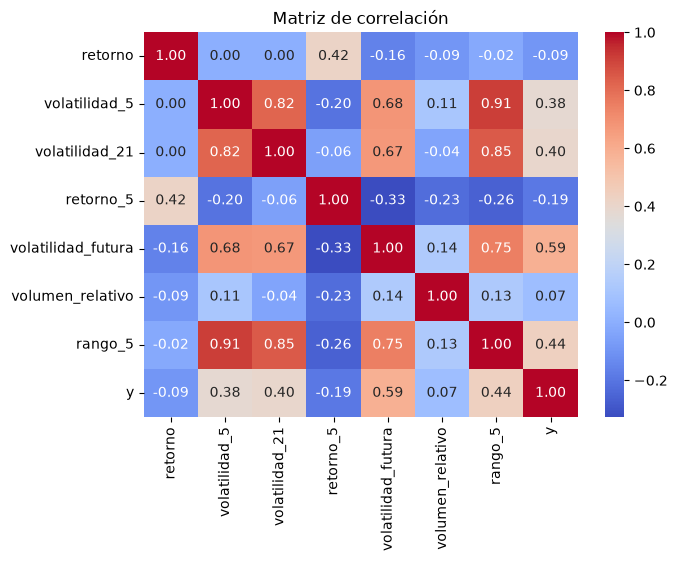

In [10]:
cols = ["retorno", "volatilidad_5", "volatilidad_21", "retorno_5",
        "volatilidad_futura", "volumen_relativo", "rango_5", "y"]

plt.figure(figsize=(7, 5))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matriz de correlación")
plt.show()

Las tres de volatilidad están muy correlacionadas entre sí (`volatilidad_5` con `rango_5`
da 0.91). Contra la volatilidad futura la que más se relaciona es `rango_5` (0.75) y la
que menos `volumen_relativo` (0.14).

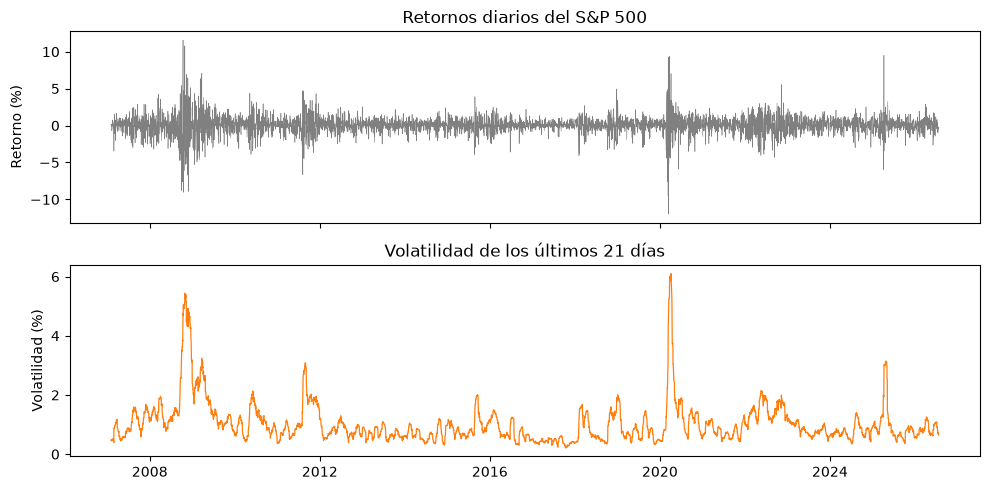

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

axes[0].plot(df.index, df["retorno"] * 100, color="gray", linewidth=0.4)
axes[0].set_ylabel("Retorno (%)")
axes[0].set_title("Retornos diarios del S&P 500")

axes[1].plot(df.index, df["volatilidad_21"] * 100, color="tab:orange", linewidth=0.9)
axes[1].set_ylabel("Volatilidad (%)")
axes[1].set_title("Volatilidad de los últimos 21 días")

plt.tight_layout()
plt.savefig("images/retornos_volatilidad.png", dpi=150)
plt.show()

Los movimientos grandes se juntan en ciertas épocas (2008, marzo de 2020) y la volatilidad
se queda alta o baja durante semanas. Es por eso que se puede predecir, lo que pasa hoy dice
bastante de los siguientes días.

## Train / test

Corto por fecha, no al azar ya que los datos no son independientes, entreno hasta 2021 y para la prueba desde enero de 2022. Los últimos
5 días de 2021 los quito porque su etiqueta usa retornos de 2022.

In [12]:
variables = ["retorno", "volatilidad_5", "volatilidad_21", "retorno_5",
             "volumen_relativo", "rango_5"]

gap = 5
train = df.loc[:"2021-12-31"].iloc[:-gap]
test = df.loc["2022-01-01":]

X_train, y_train = train[variables], train["y"]
X_test, y_test = test[variables], test["y"]

print("Train:", X_train.shape, train.index.min().date(), "-", train.index.max().date())
print("Test: ", X_test.shape, test.index.min().date(), "-", test.index.max().date())

Train: (3751, 6) 2007-02-02 - 2021-12-23
Test:  (1140, 6) 2022-01-03 - 2026-07-23


In [13]:
# el scaler se ajusta solo con train
scaler = StandardScaler()
X_train_z = scaler.fit_transform(X_train)
X_test_z = scaler.transform(X_test)


## Modelos

Validación cruzada con `TimeSeriesSplit` (siempre entrena con el pasado y valida con el
bloque siguiente), con el mismo gap de 5 días

In [14]:
cv = TimeSeriesSplit(n_splits=5, gap=5)

modelos = {
    "Regresión Logística": LogisticRegression(C=0.1, max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=55),
    "SVM": SVC(kernel="rbf", C=0.1, gamma="scale"),
}

for nombre, modelo in modelos.items():
    scores = cross_val_score(modelo, X_train_z, y_train, cv=cv, scoring="accuracy")
    modelo.fit(X_train_z, y_train)
    print(f"{nombre:<20} {np.round(scores, 4)}  promedio {scores.mean():.4f}  std {scores.std():.4f}")

Regresión Logística  [0.7184 0.6464 0.704  0.8448 0.768 ]  promedio 0.7363  std 0.0667


KNN                  [0.7136 0.6576 0.7216 0.8464 0.7616]  promedio 0.7402  std 0.0626


SVM                  [0.6512 0.4528 0.7232 0.848  0.7696]  promedio 0.6890  std 0.1343


## Resultados en test

In [15]:
preds = {nombre: modelo.predict(X_test_z) for nombre, modelo in modelos.items()}

resultados = pd.DataFrame({
    nombre: [accuracy_score(y_test, p), precision_score(y_test, p),
             recall_score(y_test, p), f1_score(y_test, p)]
    for nombre, p in preds.items()
}, index=["Accuracy", "Precision", "Recall", "F1-score"])

resultados.round(4)

,Regresión Logística,KNN,SVM
Accuracy,0.7360,0.7211,0.7368
Precision,0.8258,0.8239,0.8262
Recall,0.6795,0.6487,0.6810
F1-score,0.7456,0.7259,0.7466


In [16]:
# referencia: predecir siempre la clase mas frecuente en test
referencia = y_test.value_counts(normalize=True).max()
print("Referencia:", round(referencia, 4))
print("Alta en train:", round(y_train.mean(), 4), "| alta en test:", round(y_test.mean(), 4))

Referencia: 0.5693
Alta en train: 0.502 | alta en test: 0.5693


Los tres le ganan a la referencia por 16 % aprox.

### Intervalos de confianza

Bootstrap por bloques de 21 días, porque los días seguidos no son independientes.

In [17]:
rng = np.random.default_rng(42)
n = len(y_test)
bloque = 21

intervalos = {}
for nombre, p in preds.items():
    aciertos = (p == y_test.values).astype(int)
    accs = []
    for _ in range(2000):
        inicios = rng.integers(0, n - bloque + 1, size=n // bloque + 1)
        muestra = np.concatenate([aciertos[i:i + bloque] for i in inicios])[:n]
        accs.append(muestra.mean())
    intervalos[nombre] = np.percentile(accs, [2.5, 97.5])
    print(f"{nombre:<20} {aciertos.mean():.4f}  IC 95%: [{intervalos[nombre][0]:.4f}, {intervalos[nombre][1]:.4f}]")

Regresión Logística  0.7360  IC 95%: [0.6877, 0.7877]


KNN                  0.7211  IC 95%: [0.6710, 0.7667]


SVM                  0.7368  IC 95%: [0.6886, 0.7842]


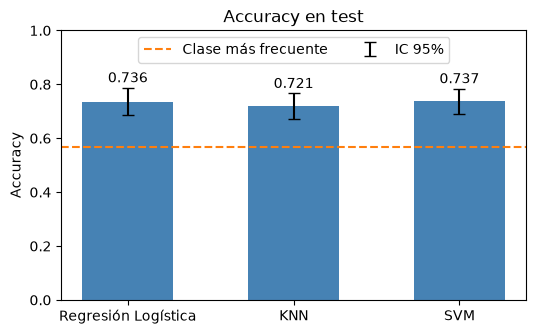

In [18]:
acc = resultados.loc["Accuracy"]
err = np.array([[acc[m] - intervalos[m][0], intervalos[m][1] - acc[m]] for m in acc.index]).T

plt.figure(figsize=(6, 3.5))
plt.bar(acc.index, acc.values, color="steelblue", width=0.55)
plt.errorbar(range(len(acc)), acc.values, yerr=err, fmt="none", color="black", capsize=4, label="IC 95%")
plt.axhline(referencia, color="tab:orange", linestyle="--", label="Clase más frecuente")

for i, v in enumerate(acc.values):
    plt.text(i, intervalos[acc.index[i]][1] + 0.02, f"{v:.3f}", ha="center")

plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Accuracy en test")
plt.legend(loc="upper center", ncol=2)
plt.savefig("images/comparacion_modelos.png", dpi=150, bbox_inches="tight")
plt.show()

### McNemar

Para comparar dos modelos sobre los mismos días. Solo toma en cuenta los días donde uno
acierta y el otro no.

In [19]:
def tabla_2x2(a, b):
    ok_a = a == y_test.values
    ok_b = b == y_test.values
    return [[np.sum(ok_a & ok_b), np.sum(ok_a & ~ok_b)],
            [np.sum(~ok_a & ok_b), np.sum(~ok_a & ~ok_b)]]

# la referencia es predecir siempre volatilidad alta
todas = {**preds, "Referencia": np.ones(n, dtype=int)}

pares = [("Regresión Logística", "SVM"), ("Regresión Logística", "KNN"), ("KNN", "SVM"),
         ("Regresión Logística", "Referencia"), ("KNN", "Referencia"), ("SVM", "Referencia")]

filas = []
for a, b in pares:
    t = tabla_2x2(todas[a], todas[b])
    filas.append({"Comparación": f"{a} vs {b}",
                  "Solo acierta el primero": t[0][1],
                  "Solo acierta el segundo": t[1][0],
                  "p-valor": mcnemar(t, exact=True).pvalue})

pd.DataFrame(filas).set_index("Comparación").round(4)

,Solo acierta el primero,Solo acierta el segundo,p-valor
Comparación,,,
Regresión Logística vs SVM,35,36,1.0000
Regresión Logística vs KNN,63,46,0.1250
KNN vs SVM,30,48,0.0535
Regresión Logística vs Referencia,398,208,0.0000
KNN vs Referencia,401,228,0.0000
SVM vs Referencia,398,207,0.0000


Contra la referencia el p-valor es prácticamente 0, asi que podemos decir que los modelos superan la referencia. Entre modelos ninguna diferencia es
significativa realmente (p > 0.05)

### Matrices de confusión

El error caro es el falso negativo: decir que estara tranquilo y que el mercado se mueva (volatilidad alta).

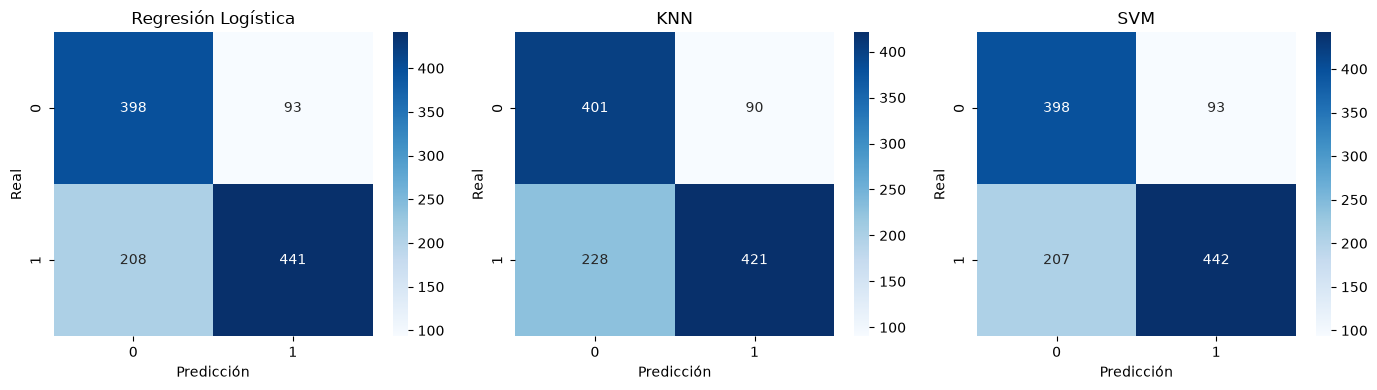

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (nombre, p) in zip(axes, preds.items()):
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(nombre)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")

plt.tight_layout()
plt.show()

In [21]:
# en que % de los dias anuncia alta cada modelo
for nombre, p in preds.items():
    print(f"{nombre:<20} {p.mean():.1%}")
print(f"{'Real':<20} {y_test.mean():.1%}")

Regresión Logística  46.8%
KNN                  44.8%
SVM                  46.9%
Real                 56.9%


KNN tiene menos falsos positivos (90) pero más falsos negativos (228 contra 207 del SVM),
justo el error que importa. Los tres anuncian alta en 45-47% de los días cuando en la
realidad fue 56.9%, de ahí el recall bajo.

## Umbral de decisión

Bajar el corte de 0.5 para que el modelo avise más seguido. Lo hago con la regresión
logística (empató con el SVM y ademas ya da probabilidades)

In [22]:
lr = modelos["Regresión Logística"]

# probabilidades de cada split
prob_val, y_val = [], []
for idx_tr, idx_va in cv.split(X_train_z):
    m = LogisticRegression(C=0.1, max_iter=1000).fit(X_train_z[idx_tr], y_train.iloc[idx_tr])
    prob_val.append(m.predict_proba(X_train_z[idx_va])[:, 1])
    y_val.append(y_train.iloc[idx_va])

prob_val = np.concatenate(prob_val)
y_val = np.concatenate(y_val)

# el mejor F1
precision_v, recall_v, umbrales_v = precision_recall_curve(y_val, prob_val)
f1_v = 2 * precision_v[:-1] * recall_v[:-1] / (precision_v[:-1] + recall_v[:-1])
umbral_decision = umbrales_v[np.argmax(f1_v)]
print(f"Umbral de decisión: {umbral_decision:.2f}")

Umbral de decisión: 0.43


In [23]:
prob_test = lr.predict_proba(X_test_z)[:, 1]
y_pred_05 = preds["Regresión Logística"]
y_pred_ajustado = (prob_test >= umbral_decision).astype(int)

def resumen(p):
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    return [f"{accuracy_score(y_test, p):.4f}", f"{precision_score(y_test, p):.4f}",
            f"{recall_score(y_test, p):.4f}", f"{f1_score(y_test, p):.4f}", fn, fp]

pd.DataFrame({"Umbral 0.50": resumen(y_pred_05),
              f"Umbral {umbral_decision:.2f}": resumen(y_pred_ajustado)},
             index=["Accuracy", "Precision", "Recall", "F1-score", "Falsos negativos", "Falsos positivos"])

,Umbral 0.50,Umbral 0.43
Accuracy,0.7360,0.7386
Precision,0.8258,0.7854
Recall,0.6795,0.7442
F1-score,0.7456,0.7642
Falsos negativos,208,166
Falsos positivos,93,132


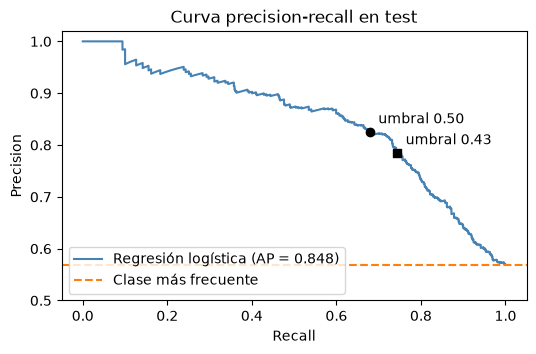

In [24]:
precision_t, recall_t, _ = precision_recall_curve(y_test, prob_test)
ap = average_precision_score(y_test, prob_test)

plt.figure(figsize=(6, 3.5))
plt.plot(recall_t, precision_t, color="steelblue", label=f"Regresión logística (AP = {ap:.3f})")
plt.axhline(y_test.mean(), color="tab:orange", linestyle="--", label="Clase más frecuente")

for p, texto, marcador in [(y_pred_05, "0.50", "o"), (y_pred_ajustado, f"{umbral_decision:.2f}", "s")]:
    r, pr = recall_score(y_test, p), precision_score(y_test, p)
    plt.scatter(r, pr, color="black", marker=marcador, zorder=3)
    plt.annotate(f"umbral {texto}", (r, pr), xytext=(6, 6), textcoords="offset points")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.ylim(0.5, 1.02)
plt.title("Curva precision-recall en test")
plt.legend(loc="lower left")
plt.show()

Con 0.43 detecta 42 días movidos más a cambio de 39 falsas alarmas más. El recall sube de
0.68 a 0.74 y el accuracy no baja.

## Peso de las variables

retorno_5          -0.419
volatilidad_5      -0.319
retorno            -0.287
volumen_relativo    0.000
volatilidad_21      0.947
rango_5             1.885
dtype: float64


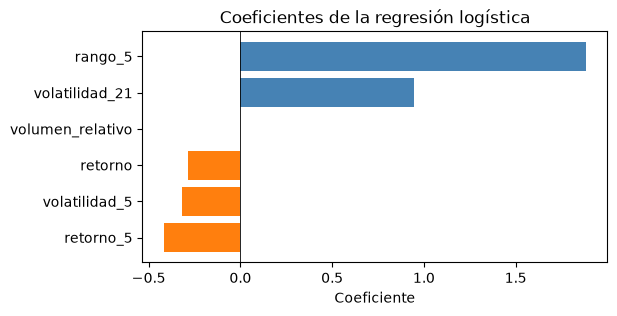

In [25]:
# coeficientes de la regresión logística
coef = pd.Series(lr.coef_[0], index=variables).sort_values()
print(coef.round(3))

plt.figure(figsize=(6, 3))
plt.barh(coef.index, coef.values, color=["tab:orange" if c < 0 else "steelblue" for c in coef])
plt.axvline(0, color="black", linewidth=0.6)
plt.xlabel("Coeficiente")
plt.title("Coeficientes de la regresión logística")
plt.show()

`rango_5` (1.885) y `volatilidad_21` (0.947) son las que más pesan y `volumen_relativo` no
aporta nada.

## Conclusiones

- Los tres modelos (~73%) le ganan a predecir siempre la clase más frecuente (56.9%).
- No hay un ganador entre ellos, pesan más las variables que el algoritmo.
- Lo que más informa es la volatilidad reciente: el rango diario y la volatilidad de 21 días.
- Bajando el umbral de decisión a 0.43 el recall sube de 0.68 a 0.74 sin perder accuracy.
